In [21]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

from tensorflow import keras
import cv2
import os

In [22]:
train_path = "C:/Users/Mahesh/Downloads/archive (2)/Training"
test_path = "C:/Users/Mahesh/Downloads/archive (2)/Testing"

classes = [
    'glioma_tumor',
    'meningioma_tumor',
    'no_tumor',
    'pituitary_tumor'
]

In [23]:
x_train = []
y_train = []

for i, category in enumerate(classes):
    path = os.path.join(train_path, category)

    for img_name in os.listdir(path):
        img_path = os.path.join(path, img_name)

        img = cv2.imread(img_path)

        if img is not None:
            img = cv2.resize(img, (32, 32))

            x_train.append(img)
            y_train.append(i)

x_train = np.array(x_train)
y_train = np.array(y_train)

print(x_train.shape)
print(y_train.shape)

(2870, 32, 32, 3)
(2870,)


In [24]:
x_test = []
y_test = []

for i, category in enumerate(classes):
    path = os.path.join(test_path, category)

    for img_name in os.listdir(path):
        img_path = os.path.join(path, img_name)

        img = cv2.imread(img_path)

        if img is not None:
            img = cv2.resize(img, (32, 32))

            x_test.append(img)
            y_test.append(i)

x_test = np.array(x_test)
y_test = np.array(y_test)

print(x_test.shape)
print(y_test.shape)

(394, 32, 32, 3)
(394,)


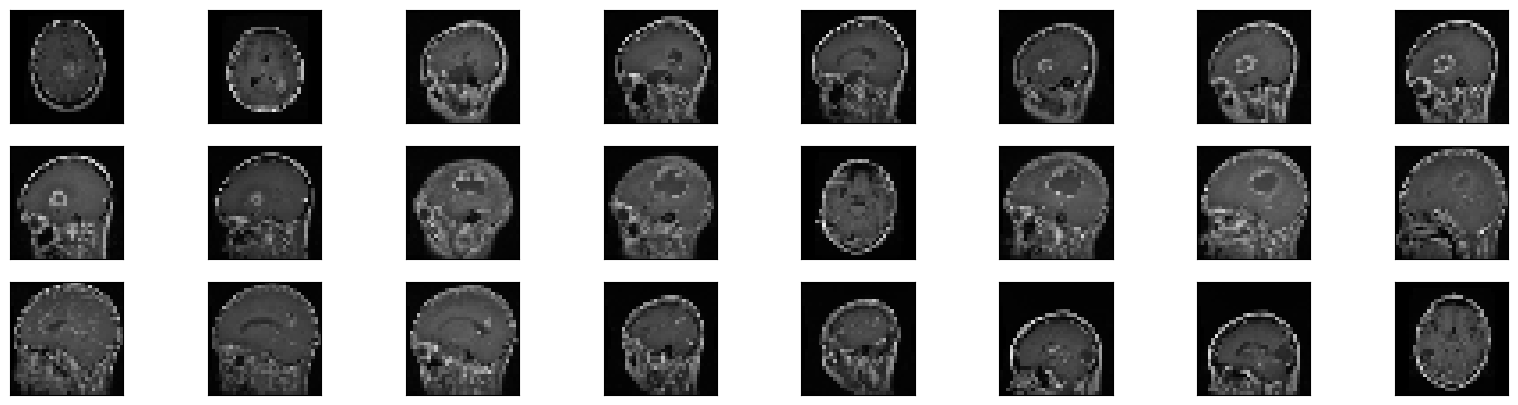

In [25]:
fig = plt.figure(figsize=(20,5))

for i in range(24):
    ax = fig.add_subplot(3, 8, i + 1, xticks=[], yticks=[])
    ax.imshow(cv2.cvtColor(x_train[i], cv2.COLOR_BGR2RGB))

In [26]:
x_train = x_train.astype('float32') / 255
x_test = x_test.astype('float32') / 255

In [27]:
num_classes = 4

y_train = keras.utils.to_categorical(y_train, num_classes)
y_test = keras.utils.to_categorical(y_test, num_classes)

print(y_train.shape)
print(y_test.shape)

(2870, 4)
(394, 4)


In [28]:
(x_train, x_valid) = x_train[500:], x_train[:500]
(y_train, y_valid) = y_train[500:], y_train[:500]

print(x_train.shape)
print(x_valid.shape)
print(y_train.shape)
print(y_valid.shape)

(2370, 32, 32, 3)
(500, 32, 32, 3)
(2370, 4)
(500, 4)


In [29]:
from keras.models import Sequential
from keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

model = Sequential()

model.add(Conv2D(filters=16, kernel_size=2, padding='same',
                 activation='relu', input_shape=(32, 32, 3)))

model.add(MaxPooling2D(pool_size=2))

model.add(Conv2D(filters=32, kernel_size=2,
                 padding='same', activation='relu'))

model.add(MaxPooling2D(pool_size=2))

model.add(Conv2D(filters=64, kernel_size=2,
                 padding='same', activation='relu'))

model.add(MaxPooling2D(pool_size=2))

model.add(Dropout(0.3))

model.add(Flatten())

model.add(Dense(500, activation='relu'))

model.add(Dropout(0.4))

model.add(Dense(4, activation='softmax'))

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)                    │ (None, 32, 32, 16)          │             208 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 16, 16, 16)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_4 (Conv2D)                    │ (None, 16, 16, 32)          │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_4 (MaxPooling2D)       │ (None, 8, 8, 32)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_5 (Conv2D)                    │ (None, 8, 8, 64)            │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_5 (MaxPooling2D)       │ (None, 4, 4, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 4, 4, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_1 (Flatten)                  │ (None, 1024)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 500)                 │         512,500 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_3 (Dropout)                  │ (None, 500)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 4)                   │           2,004 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 525,048 (2.00 MB)

 Trainable params: 525,048 (2.00 MB)

 Non-trainable params: 0 (0.00 B)

In [30]:
model.compile(
    loss='categorical_crossentropy',
    optimizer='rmsprop',
    metrics=['accuracy']
)

In [31]:
from keras.callbacks import ModelCheckpoint

checkpointer = ModelCheckpoint(
    filepath='model.weights.best.keras',
    save_best_only=True
)

hist = model.fit(
    x_train,
    y_train,
    batch_size=32,
    epochs=100,
    validation_data=(x_valid, y_valid),
    callbacks=[checkpointer],
    verbose=1,
    shuffle=True
)

Epoch 1/100
75/75 ━━━━━━━━━━━━━━━━━━━━ 7s 36ms/step - accuracy: 0.5224 - loss: 1.1044 - val_accuracy: 0.0000e+00 - val_loss: 3.4794
Epoch 2/100
75/75 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - accuracy: 0.6646 - loss: 0.8357 - val_accuracy: 0.2500 - val_loss: 1.8026
Epoch 3/100
75/75 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - accuracy: 0.7291 - loss: 0.6925 - val_accuracy: 0.0220 - val_loss: 2.5460
Epoch 4/100
75/75 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - accuracy: 0.7544 - loss: 0.6327 - val_accuracy: 0.4420 - val_loss: 1.2221
Epoch 5/100
75/75 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - accuracy: 0.7785 - loss: 0.5668 - val_accuracy: 0.2360 - val_loss: 1.9744
Epoch 6/100
75/75 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - accuracy: 0.7937 - loss: 0.5241 - val_accuracy: 0.8020 - val_loss: 0.5193
Epoch 7/100
75/75 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - accuracy: 0.8042 - loss: 0.4951 - val_accuracy: 0.3720 - val_loss: 1.7521
Epoch 8/100
75/75 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - accuracy: 0.8266 - loss: 0.4364 - val_accuracy

In [32]:
y_hat = model.predict(x_test)

13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step


In [33]:
score = model.evaluate(x_test, y_test, verbose=0)

accuracy = 100 * score[1]

print('Test accuracy: %.4f%%' % accuracy)

Test accuracy: 69.0355%


In [34]:
brain_tumor_labels = [
    'glioma_tumor',
    'meningioma_tumor',
    'no_tumor',
    'pituitary_tumor'
]

In [35]:
import tensorflow as tf

img = keras.preprocessing.image.load_img(
    os.path.join(test_path, 'glioma_tumor', os.listdir(os.path.join(test_path, 'glioma_tumor'))[0]),
    target_size=(32, 32)
)

img_array = keras.preprocessing.image.img_to_array(img)

img_array = img_array / 255.0

img_array = tf.expand_dims(img_array, 0)

predictions = model.predict(img_array)

predictions

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 130ms/step


array([[1.0062627e-16, 2.3951635e-02, 9.5341247e-01, 2.2635950e-02]],
      dtype=float32)

In [36]:
brain_tumor_labels[np.argmax(predictions)]

'no_tumor'